# Linearity Check — A Complete, Practical Guide

---

Linear Regression assumes it can describe a relationship with a **straight-line term**:

$$\text{LogRate} = \beta_0 + \beta_1 \times \text{BuildingSize}$$

That equation *always* draws a straight line. A **linearity check** asks the one question that
decides whether this is acceptable:

> **Does the relationship between a feature (X) and the target (Y) look approximately like a straight line?**

This notebook works through **6 methods**, each on real data, then combines them into one repeatable workflow.

| # | Method | What it tells you | Section |
|---|--------|-------------------|---------|
| 1 | Scatter plot (+ binned medians) | The *shape* of the relationship, by eye | §5 |
| 2 | Pearson correlation `r` | Strength of the **linear** relationship | §6 |
| 3 | Spearman correlation `ρ` | Strength of the **monotonic** relationship (ranks) | §8 |
| 4 | Plot the transformed feature | Whether `log(X)` / `sqrt(X)` straightens it out | §10 |
| 5 | Add a quadratic term | Lets the fitted line *bend* | §11 |
| 6 | Residual plot | Formal check for **left-over curvature** after fitting | §12 |

**The three questions the whole check answers, in order:**

1. Is there a relationship **at all**?  → Pearson / Spearman
2. Is it roughly a **straight line**?  → scatter plots + the Pearson-vs-Spearman gap
3. If curved, can a **transformation** fix it?  → `log(X)`, `sqrt(X)`, `X²` — then *validate on unseen data*

---
## 0. Imports

Everything here uses `pandas`, `numpy`, `matplotlib` and `scikit-learn` only.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

%matplotlib inline
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 120)

rng = np.random.default_rng(42)
print("ready")

ready


---
## 1. What Is a Linearity Check?

A linearity check asks **one** question:

> Does the relationship between a feature (X) and the target (Y) look approximately like a straight line?

The model term `β1 × X` can only ever produce a straight line. So if the *real* relationship curves,
a single straight-line term cannot represent it — and the model's predictions will be **systematically**
off, not just randomly off.

A linearity check is therefore **not** "is Pearson `r` high?". It is a short investigation:

```
raw feature
    ↓  look at it            (scatter, binned medians)
    ↓  measure it            (Pearson vs Spearman)
    ↓  if curved, transform  (log / sqrt / square)
    ↓  re-measure            (did Pearson improve?)
    ↓  fit and check         (residual plot)
    ↓  validate             (out-of-sample R², not training R²)
final model
```

---
## 2. Why Does Linearity Matter?

Imagine the true relationship **drops quickly at first, then levels off** — but your model can only
draw a straight line. The straight line will **overshoot in some regions and undershoot in others**.

> ⚠️ This isn't a cosmetic detail. A forced straight line on a curved relationship means the model is
> **consistently wrong in predictable ways** — which is worse than being randomly a little bit off.
> Random error averages out; systematic error does not.

The cell below makes this concrete: the truth is a curve, the fit is a line, and the residuals
(errors) show a clear arc instead of formless noise.

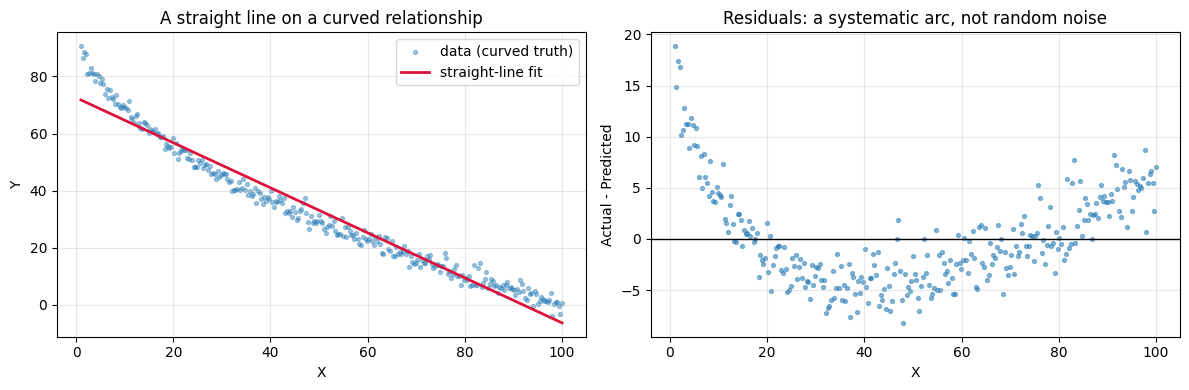

Mean residual per X band (0 would mean unbiased):
X_band
(0.999, 20.8]    4.74
(20.8, 40.6]    -3.84
(40.6, 60.4]    -3.73
(60.4, 80.2]    -0.86
(80.2, 100.0]    3.69
Name: residual, dtype: float64

Training R^2 is still 0.958 - a decent R^2 does NOT prove the shape is right (see 13.4).


In [4]:
# --- A curved truth, fitted with a straight line -------------------------
x = np.linspace(1, 100, 300)
y_true = 100 - 10 * np.sqrt(x)                 # curved: steep, then flattens
y = y_true + rng.normal(0, 2.0, size=x.size)   # add a little noise

lin = LinearRegression().fit(x.reshape(-1, 1), y)
y_hat = lin.predict(x.reshape(-1, 1))
resid = y - y_hat

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(x, y, s=8, alpha=0.4, label="data (curved truth)")
ax[0].plot(x, y_hat, color="crimson", lw=2, label="straight-line fit")
ax[0].set_title("A straight line on a curved relationship")
ax[0].set_xlabel("X"); ax[0].set_ylabel("Y"); ax[0].legend()

ax[1].scatter(x, resid, s=8, alpha=0.5)
ax[1].axhline(0, color="black", lw=1)
ax[1].set_title("Residuals: a systematic arc, not random noise")
ax[1].set_xlabel("X"); ax[1].set_ylabel("Actual - Predicted")

plt.tight_layout(); plt.show()

# Where is the model biased? Average error by region of X:
bias = pd.DataFrame({"X_band": pd.qcut(x, 5), "residual": resid}) \
         .groupby("X_band", observed=True)["residual"].mean().round(2)
print("Mean residual per X band (0 would mean unbiased):")
print(bias)
print(f"\nTraining R^2 is still {lin.score(x.reshape(-1,1), y):.3f} "
      "- a decent R^2 does NOT prove the shape is right (see 13.4).")

---
## 3. What Exactly Does "Linear" Mean?

A relationship is **linear** when a change in X produces a **constant** change in Y — the same
amount, every time.

| Example | X = 1 | X = 2 | X = 3 | X = 4 | Change per step? |
|---|---|---|---|---|---|
| `Y = 100 − 2X` | 98 | 96 | 94 | 92 | always −2 → **linear** |
| `Y = 100 − 10√X` | 90 | ≈85.9 | ≈82.7 | 80 | shrinks each time → **nonlinear** |

"Linear" is about **constant differences**, not about "goes up" or "goes down".
The cell below checks this numerically with `np.diff`.

 X  Y = 100-2X  Y = 100-10*sqrt(X)
 1          98               90.00
 2          96               85.86
 3          94               82.68
 4          92               80.00
 5          90               77.64

Step-to-step change (np.diff):
  100-2X          : [-2 -2 -2 -2]
  100-10*sqrt(X)  : [-4.14 -3.18 -2.68 -2.36]

-> constant differences = linear;  shrinking differences = nonlinear


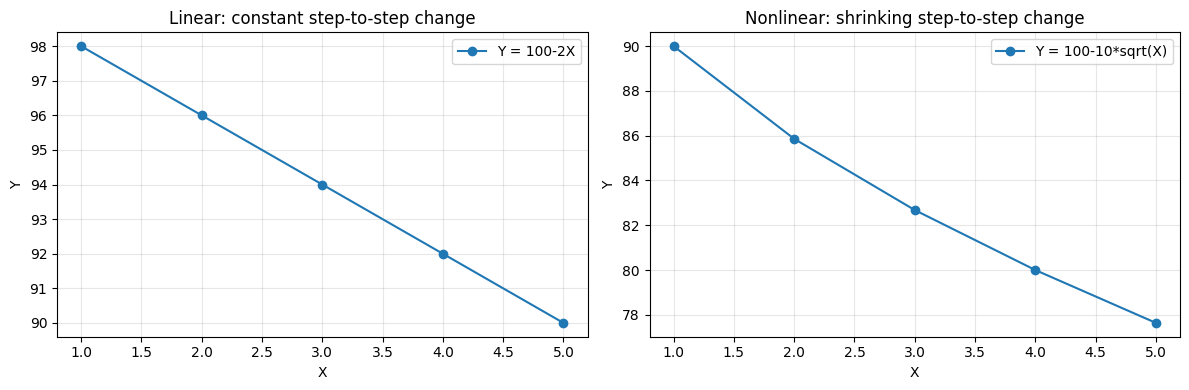

In [5]:
xs = np.arange(1, 6)
tbl = pd.DataFrame({
    "X":              xs,
    "Y = 100-2X":     100 - 2 * xs,
    "Y = 100-10*sqrt(X)": (100 - 10 * np.sqrt(xs)).round(2),
})
print(tbl.to_string(index=False))

print("\nStep-to-step change (np.diff):")
print("  100-2X          :", np.diff(tbl["Y = 100-2X"].values))
print("  100-10*sqrt(X)  :", np.diff(tbl["Y = 100-10*sqrt(X)"].values).round(2))
print("\n-> constant differences = linear;  shrinking differences = nonlinear")

fig, (a1,a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(tbl["X"], tbl["Y = 100-2X"], marker="o", label="Y = 100-2X")
a1.set_title("Linear: constant step-to-step change")
a1.set_xlabel("X"); a1.set_ylabel("Y"); a1.legend()
a2.plot(tbl["X"], tbl["Y = 100-10*sqrt(X)"], marker="o", label="Y = 100-10*sqrt(X)")
a2.set_title("Nonlinear: shrinking step-to-step change")
a2.set_xlabel("X"); a2.set_ylabel("Y"); a2.legend()
plt.tight_layout(); plt.show()

---
## 4. Applying This to a Real Model

We use the Melbourne housing dataset. In a property model the target is usually the **log of the rate**
(price per square metre), not the raw price:

```python
d["Rate"]    = d["Price"] / d["BuildingArea"]   # $ per m^2
d["LogRate"] = np.log(d["Rate"])
```

Two reasons for the log: rates are strongly right-skewed, and on the log scale a coefficient reads as an
approximate **percentage** effect.

So the real question becomes: **is the relationship between each predictor and `LogRate` approximately linear?**

| Predictor | Meaning | Target |
|---|---|---|
| `log_building` | `log(BuildingArea)` — size of the dwelling | `LogRate` |
| `log_land` | `log(Landsize)` — size of the block | `LogRate` |
| `Age` | `2018 − YearBuilt` | `LogRate` |
| `coverage` | `BuildingArea / Landsize` — how much of the block is built on | `LogRate` |
| `Distance` | km to the CBD | `LogRate` |

> 📌 **One honest caveat about this dataset.** `Rate` is `Price / BuildingArea`, so `BuildingArea`
> appears in the *denominator of the target*. Part of the `log_building` ↔ `LogRate` relationship is
> therefore **arithmetic**, not economic, and that particular coefficient must be read with care.
> This is standard practice in rate-based property models, and it does **not** affect the linearity
> *procedure* we are learning — but it is exactly the kind of thing worth noticing before you
> interpret a number.

In [6]:
# --- Load and prepare ----------------------------------------------------
df = pd.read_csv("../data/melb_data.csv")

d = df[["Price", "BuildingArea", "Landsize", "YearBuilt", "Distance", "Rooms"]].dropna().copy()

# Basic sanity filters: a building under 30 m^2 or a zero-size block is a data error,
# and YearBuilt has impossible values (the raw minimum is 1196).
d = d[(d["Price"] > 0) &
      (d["BuildingArea"] >= 30) &
      (d["Landsize"] > 0) &
      d["YearBuilt"].between(1850, 2018)]

d["Rate"] = d["Price"] / d["BuildingArea"]

# Trim the 1% tails of Rate: a handful of extreme values can dominate a correlation.
lo, hi = d["Rate"].quantile([0.01, 0.99])
d = d[d["Rate"].between(lo, hi)].reset_index(drop=True)

# --- Target and predictors ----------------------------------------------
d["LogRate"]      = np.log(d["Rate"])
d["log_building"] = np.log(d["BuildingArea"])
d["log_land"]     = np.log(d["Landsize"])
d["Age"]          = 2018 - d["YearBuilt"]
d["coverage"]     = d["BuildingArea"] / d["Landsize"]

print(f"rows after cleaning: {len(d):,}")
print(d[["Rate", "LogRate", "BuildingArea", "Landsize", "Age", "coverage", "Distance"]]
      .describe().T[["min", "25%", "50%", "75%", "max"]].round(2))

rows after cleaning: 5,660
                  min      25%      50%      75%       max
Rate          2429.67  5558.67  7363.88  9501.24  18589.74
LogRate          7.80     8.62     8.90     9.16      9.83
BuildingArea    30.00   105.58   135.00   181.00    720.00
Landsize         1.00   258.00   506.50   665.00  37000.00
Age              0.00    21.00    53.00    83.00    168.00
coverage         0.00     0.22     0.34     0.54     62.00
Distance         0.00     6.70     9.90    13.50     47.40


---
## 5. Method 1 — Scatter Plot

The simplest linearity check: **plot the feature against the target and look at it.**

```python
plt.scatter(d["log_building"], d["LogRate"])
plt.xlabel("log_building")
plt.ylabel("LogRate")
plt.show()
```

You are visually asking: do the points follow something **roughly straight**, or do they **bend**?

The red line in each panel below is the straight-line fit — it is there to give your eye a reference:
where the cloud of points drifts consistently above or below the line, the relationship is curving.

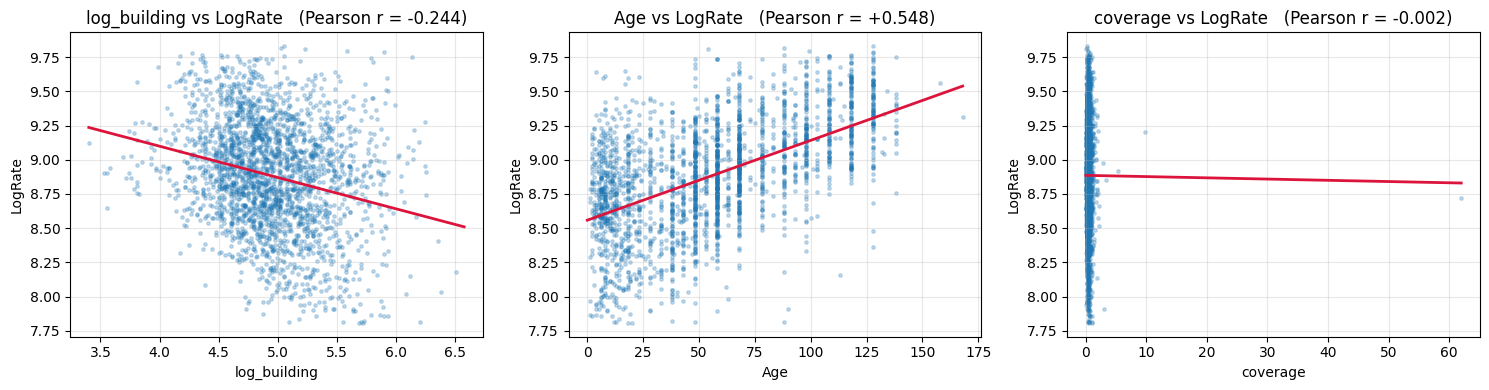

In [7]:
def scatter_with_fit(ax, xcol, ycol="LogRate", data=None, sample=2500):
    # Scatter of xcol vs ycol with the straight-line fit overlaid.
    data = d if data is None else data
    s = data.sample(min(sample, len(data)), random_state=0)
    ax.scatter(s[xcol], s[ycol], s=6, alpha=0.25)
    m = LinearRegression().fit(data[[xcol]], data[ycol])
    xs = pd.DataFrame({xcol: np.linspace(data[xcol].min(), data[xcol].max(), 50)})
    ax.plot(xs[xcol], m.predict(xs), color="crimson", lw=2)
    r = data[xcol].corr(data[ycol])
    ax.set_title(f"{xcol} vs {ycol}   (Pearson r = {r:+.3f})")
    ax.set_xlabel(xcol); ax.set_ylabel(ycol)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["log_building", "Age", "coverage"]):
    scatter_with_fit(a, col)
plt.tight_layout(); plt.show()

### 5.1 Why Use Binned Medians?

Real data is **noisy** — thousands of overlapping points make a raw scatter plot hard to read.
Grouping X into bins and plotting the **median Y per bin** strips out the noise and reveals the
underlying pattern much more clearly.

The median (not the mean) is used deliberately: it is not dragged around by a few extreme sales.

           sales  median_rate  pct_change
size_band                                
<80          478       8291.0         NaN
80-110      1213       8015.0        -3.3
110-140     1386       7240.0        -9.7
140-180     1151       6875.0        -5.0
180-250      907       6649.0        -3.3
250+         525       6634.0        -0.2


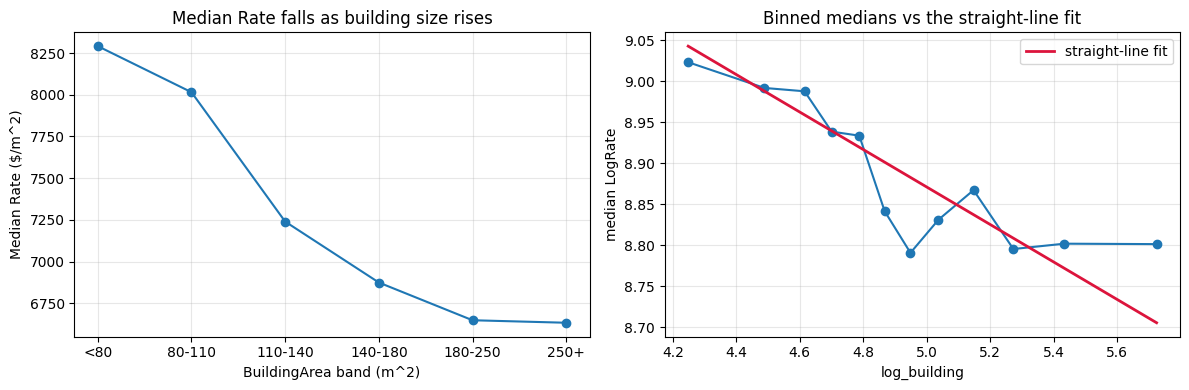

In [8]:
# --- Binned medians: median Rate per building-size band ------------------
bins   = [0, 80, 110, 140, 180, 250, np.inf]
labels = ["<80", "80-110", "110-140", "140-180", "180-250", "250+"]
d["size_band"] = pd.cut(d["BuildingArea"], bins=bins, labels=labels)

binned = (d.groupby("size_band", observed=True)
            .agg(sales=("Rate", "size"), median_rate=("Rate", "median"))
            .round(0))
binned["pct_change"] = (binned["median_rate"].pct_change() * 100).round(1)
print(binned.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(binned.index.astype(str), binned["median_rate"], marker="o")
ax[0].set_title("Median Rate falls as building size rises")
ax[0].set_xlabel("BuildingArea band (m^2)"); ax[0].set_ylabel("Median Rate ($/m^2)")

# Same idea on the modelling scale, using quantile bins
q = pd.qcut(d["log_building"], 12)
med = d.groupby(q, observed=True).agg(log_building=("log_building", "median"), y=("LogRate", "median"))
ax[1].plot(med["log_building"], med["y"], marker="o")
m = LinearRegression().fit(d[["log_building"]], d["LogRate"])
ax[1].plot(med["log_building"], m.predict(med[["log_building"]]), color="crimson", lw=2,
           label="straight-line fit")
ax[1].set_title("Binned medians vs the straight-line fit")
ax[1].set_xlabel("log_building"); ax[1].set_ylabel("median LogRate"); ax[1].legend()

plt.tight_layout(); plt.show()

**Reading the percentage drops between bins:** the decreases are *not identical* — the rate falls
steeply at first and then flattens. That is the signature of a **nonlinear** relationship, and exactly
why we would investigate a transformation such as `log(BuildingArea)`.

Notice also that the binned-median line (right panel) does not lie exactly on the red fit — it wanders
slightly above and below it. **Whether that wander is real curvature or just noise is not something the
eye can settle**; §12 measures it and §15.2 decides whether it is worth modelling.

---
## 6. Method 2 — Pearson Correlation

**Pearson correlation (`r`)** measures the **strength and direction of a *linear* relationship**
between two numeric variables. It always falls between **−1 and +1**.

| Pearson `r` | Meaning |
|---|---|
| **+1** | perfect positive linear relationship |
| +0.7 | strong positive linear relationship |
| +0.3 | moderate positive relationship |
| **0** | no *linear* relationship |
| −0.3 | moderate negative relationship |
| −0.7 | strong negative relationship |
| **−1** | perfect negative linear relationship |

### 6.1 The Formula (Don't Worry About Memorising It)

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \times \sum (y_i - \bar{y})^2}}$$

The idea, in plain steps:

1. Find how far each **X** is from its average.
2. Find how far each **Y** is from its average.
3. See whether they **move together** (both above average? both below?).
4. **Standardise** the result so it lands between −1 and +1.

In pandas it is one line: `d["log_building"].corr(d["LogRate"])`

by hand : -0.244186
pandas  : -0.244186

Perfect example (Y drops by exactly 2 every step):
 X  Y
 1 10
 2  8
 3  6
 4  4
 5  2
Pearson r = -0.9999999999999999


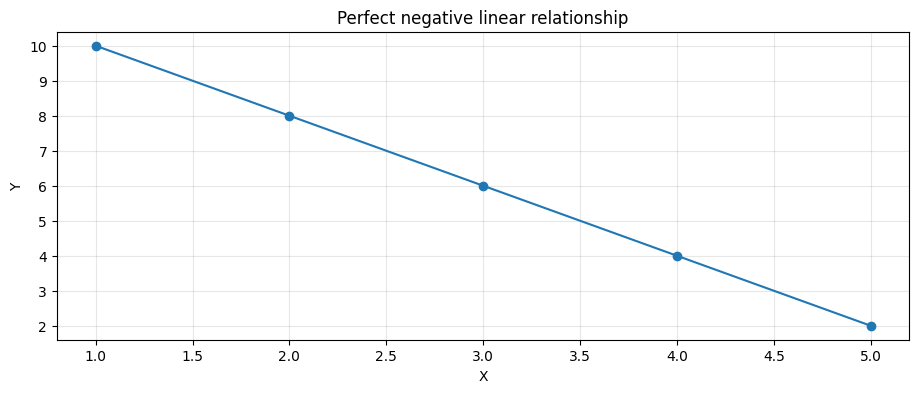

In [9]:
# --- Pearson from the formula, then from pandas (they must agree) --------
def pearson_by_hand(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    dx, dy = x - x.mean(), y - y.mean()
    return (dx * dy).sum() / np.sqrt((dx**2).sum() * (dy**2).sum())

print("by hand :", round(pearson_by_hand(d["log_building"], d["LogRate"]), 6))
print("pandas  :", round(d["log_building"].corr(d["LogRate"]), 6))

# --- 6.2 A simple perfect example ---------------------------------------
perfect = pd.DataFrame({"X": [1, 2, 3, 4, 5], "Y": [10, 8, 6, 4, 2]})
print("\nPerfect example (Y drops by exactly 2 every step):")
print(perfect.to_string(index=False))
print("Pearson r =", perfect["X"].corr(perfect["Y"]))   # exactly -1.0
plt.plot(perfect["X"], perfect["Y"], marker="o")
plt.title("Perfect negative linear relationship")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()  

---
## 7. What Pearson Does **NOT** Tell You

> 🧠 **This is one of the most important ideas in this notebook.**
> A low Pearson `r` does **not** mean "no relationship".
> It only means **"no strong *linear* relationship"**.

The classic example is `Y = X²` on data centred at zero. The relationship is perfectly deterministic —
yet Pearson `r ≈ 0`, because the positive side (X > 0) and the negative side (X < 0) pull the
correlation in **opposite directions and cancel out**.

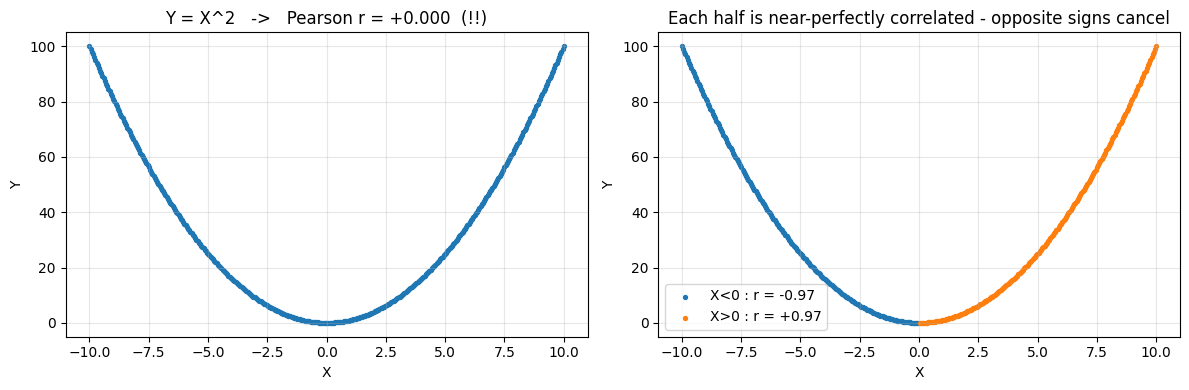

Pearson over the whole range : 0.0
There is obviously a relationship - it is just not a straight line.


In [10]:
x2 = np.linspace(-10, 10, 400)
y2 = x2 ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(x2, y2, s=8)
ax[0].set_title(f"Y = X^2   ->   Pearson r = {np.corrcoef(x2, y2)[0,1]:+.3f}  (!!)")
ax[0].set_xlabel("X"); ax[0].set_ylabel("Y")

# The cancellation, made visible: correlation on each half is very strong
left, right = x2 < 0, x2 > 0
ax[1].scatter(x2[left],  y2[left],  s=8, label=f"X<0 : r = {np.corrcoef(x2[left],  y2[left])[0,1]:+.2f}")
ax[1].scatter(x2[right], y2[right], s=8, label=f"X>0 : r = {np.corrcoef(x2[right], y2[right])[0,1]:+.2f}")
ax[1].set_title("Each half is near-perfectly correlated - opposite signs cancel")
ax[1].set_xlabel("X"); ax[1].set_ylabel("Y"); ax[1].legend()

plt.tight_layout(); plt.show()

print("Pearson over the whole range :", round(float(np.corrcoef(x2, y2)[0, 1]), 4))
print("There is obviously a relationship - it is just not a straight line.")

---
## 8. Method 3 — Spearman Correlation

**Spearman correlation (`ρ`)** measures the strength of a **monotonic** relationship. Instead of using
the actual values, it uses their **ranks**.

### 8.1 What Does "Monotonic" Mean?

A monotonic relationship moves **consistently in one direction** — always increasing, or always
decreasing — but it does **not** have to be a straight line. **A curve can be perfectly monotonic.**

### 8.2 Worked Example

| X | X rank | Y | Y rank |
|---|---|---|---|
| 100 | 1 | 50 | 5 |
| 200 | 2 | 40 | 4 |
| 300 | 3 | 30 | 3 |
| 400 | 4 | 20 | 2 |
| 500 | 5 | 10 | 1 |

The rankings are perfectly opposite, so **Spearman ρ = −1** — and we never once checked whether the
actual values changed by a constant amount.

```python
pearson  = d["log_building"].corr(d["LogRate"], method="pearson")
spearman = d["log_building"].corr(d["LogRate"], method="spearman")
```

In [11]:
# --- Spearman is just Pearson applied to the ranks ----------------------
ex = pd.DataFrame({"X": [100, 200, 300, 400, 500], "Y": [50, 40, 30, 20, 10]})
ex["X_rank"] = ex["X"].rank()
ex["Y_rank"] = ex["Y"].rank()
print(ex.to_string(index=False))
print("\nSpearman rho          :", ex["X"].corr(ex["Y"], method="spearman"))
print("Pearson on the ranks  :", ex["X_rank"].corr(ex["Y_rank"]), " <- identical by construction")

# --- Why it matters: a strong CURVE that Pearson under-reports ----------
xc = np.linspace(1, 100, 400)
yc = np.log(xc)                      # monotonic, but strongly curved
sc = pd.DataFrame({"x": xc, "y": yc})
print(f"\nY = log(X):  Pearson = {sc['x'].corr(sc['y']):+.3f}   "
      f"Spearman = {sc['x'].corr(sc['y'], method='spearman'):+.3f}")
print("Spearman = 1.000 exactly: the ORDER is perfect even though the LINE is not.")

  X  Y  X_rank  Y_rank
100 50     1.0     5.0
200 40     2.0     4.0
300 30     3.0     3.0
400 20     4.0     2.0
500 10     5.0     1.0

Spearman rho          : -0.9999999999999999
Pearson on the ranks  : -0.9999999999999999  <- identical by construction

Y = log(X):  Pearson = +0.904   Spearman = +1.000
Spearman = 1.000 exactly: the ORDER is perfect even though the LINE is not.


---
## 9. Why Calculate **Both** Pearson and Spearman?

Comparing the two tells you not just *whether* a relationship exists, but **what shape** it has.

| Pearson | Spearman | Likely interpretation | What to do |
|---|---|---|---|
| High (−0.80) | High (−0.82) | strong **and** approximately linear | use as-is |
| Low (−0.40) | High (−0.80) | strong but **nonlinear** | try `log(X)`, `sqrt(X)`, `X²` |
| Low (−0.05) | Low (−0.08) | little **univariate** signal | **don't automatically drop it** — it may still help once other variables are controlled for |

> 💡 **Simple rule:**
> `|Pearson| ≈ |Spearman|` → probably fairly linear.
> `|Spearman|` **much bigger** than `|Pearson|` → probably nonlinear, worth transforming.

The cell below computes both for every predictor and prints an automatic diagnosis.

In [12]:
# Two questions, reported separately - they are independent of each other:
#   SIGNAL: is there a relationship at all?   (how big is max(|P|, |S|)?)
#   SHAPE : is it straight?                   (how big is |S| - |P|?)
# The thresholds below are rules of thumb for triage, NOT statistical laws (see 13.1).
SIGNAL_STRONG, SIGNAL_SOME = 0.40, 0.15
GAP_WORTH_A_LOOK = 0.05

def pearson_spearman_table(data, features, target="LogRate"):
    rows = []
    for f in features:
        p = data[f].corr(data[target], method="pearson")
        s = data[f].corr(data[target], method="spearman")
        gap = abs(s) - abs(p)

        strength = max(abs(p), abs(s))
        if strength >= SIGNAL_STRONG:
            signal = "strong"
        elif strength >= SIGNAL_SOME:
            signal = "moderate"
        else:
            signal = "weak - test in the model, do not drop yet"

        shape = "try a transformation" if gap > GAP_WORTH_A_LOOK else "straight enough"

        rows.append({"feature": f, "pearson": round(p, 3), "spearman": round(s, 3),
                     "|S|-|P|": round(gap, 3), "signal": signal, "shape": shape})
    return pd.DataFrame(rows)

features = ["BuildingArea", "log_building", "Landsize", "log_land",
            "Age", "coverage", "Distance", "Rooms"]
print(pearson_spearman_table(d, features).to_string(index=False))

     feature  pearson  spearman  |S|-|P|                                    signal                shape
BuildingArea   -0.228    -0.232    0.004                                  moderate      straight enough
log_building   -0.244    -0.232   -0.013                                  moderate      straight enough
    Landsize   -0.026    -0.098    0.072 weak - test in the model, do not drop yet try a transformation
    log_land   -0.112    -0.098   -0.014 weak - test in the model, do not drop yet      straight enough
         Age    0.548     0.543   -0.005                                    strong      straight enough
    coverage   -0.002    -0.020    0.018 weak - test in the model, do not drop yet      straight enough
    Distance   -0.538    -0.559    0.020                                    strong      straight enough
       Rooms   -0.182    -0.181   -0.001                                  moderate      straight enough


**How to read this output on our data:**

* **`Age` (+0.55 / +0.54) and `Distance` (−0.54 / −0.56)** — strong signal, and the two coefficients
  agree closely → **strong *and* roughly linear**. Use as-is.
* **`BuildingArea` (−0.23 / −0.23)** — moderate signal, no gap. Straight enough on this scale.
* **`Landsize` (−0.03 / −0.10)** — weak overall, *but* Spearman is nearly **four times** Pearson in
  magnitude. The ordering carries signal a straight line on the raw scale cannot see: this is the
  "**transform me**" signature, and §10 confirms it — `log_land` reaches −0.11, four times the raw
  Pearson.
* **`coverage` (−0.002 / −0.02)** — nothing on either measure. Note the recommendation is **not**
  "delete the feature": a variable can look like noise on its own and still matter once size and
  location are held constant. §13.2 actually tests that.

> ⚠️ **Note what did *not* happen: no feature here screams "strongly nonlinear".** The gaps are
> genuine but small. Real datasets usually look like this — the dramatic textbook `Y = X²` case is
> rare, and most of the skill is in judging **small** signals, which is exactly why the final
> out-of-sample check in §15.2 matters so much.

---
## 10. Method 4 — Plot the **Transformed** Feature

If the raw feature looks curved, transform it and plot it **again**:

```python
d["log_building"] = np.log(d["BuildingArea"])
```

### 10.1 Why Does a Log Transformation Help?

Raw values like `100 → 200 → 400 → 800 → 1600` have **rapidly growing gaps**
(+100, +200, +400, +800) — the large values dominate everything. Taking the log turns those
multiplicative steps into **equal additive steps**, so the scale is compressed and the relationship
often straightens out.

| Raw | 100 | 200 | 400 | 800 | 1600 |
|---|---|---|---|---|---|
| gap to next | +100 | +200 | +400 | +800 | — |
| `log` | 4.61 | 5.30 | 5.99 | 6.68 | 7.38 |
| gap to next | **+0.69** | **+0.69** | **+0.69** | **+0.69** | — |

raw       : [ 100  200  400  800 1600]  gaps: [100 200 400 800]
log(raw)  : [4.61 5.3  5.99 6.68 7.38]  gaps: [0.69 0.69 0.69 0.69] <- constant


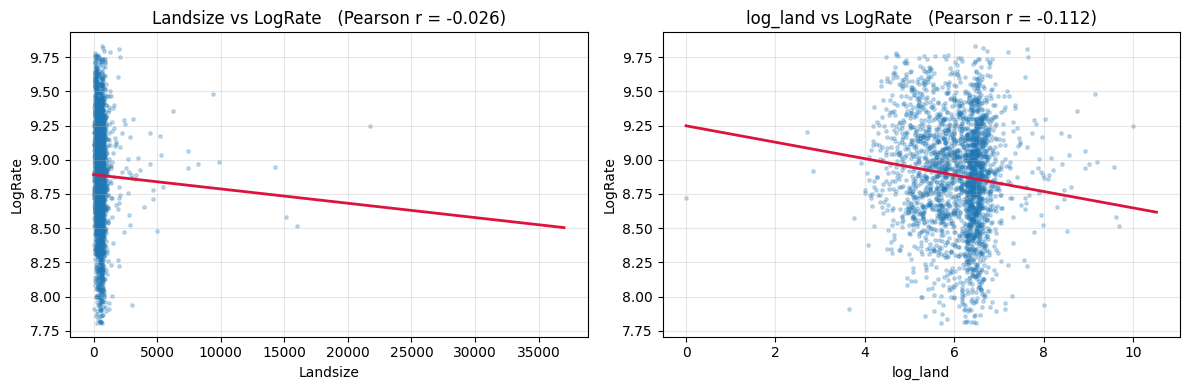

 raw feature  Pearson (raw)  Pearson (log)  Spearman (either) more linear?
BuildingArea         -0.228         -0.244             -0.232          YES
    Landsize         -0.026         -0.112             -0.098          YES


In [13]:
raw = np.array([100, 200, 400, 800, 1600])
print("raw       :", raw, " gaps:", np.diff(raw))
print("log(raw)  :", np.log(raw).round(2), " gaps:", np.diff(np.log(raw)).round(2), "<- constant")

# --- Same data, raw scale vs log scale ----------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
scatter_with_fit(ax[0], "Landsize")
scatter_with_fit(ax[1], "log_land")
plt.tight_layout(); plt.show()

# --- Did the transformation actually make it more linear? ---------------
pairs = [("BuildingArea", "log_building"), ("Landsize", "log_land")]
rows = []
for raw_col, log_col in pairs:
    rows.append({
        "raw feature": raw_col,
        "Pearson (raw)": round(d[raw_col].corr(d["LogRate"]), 3),
        "Pearson (log)": round(d[log_col].corr(d["LogRate"]), 3),
        "Spearman (either)": round(d[raw_col].corr(d["LogRate"], method="spearman"), 3),
    })
out = pd.DataFrame(rows)
out["more linear?"] = np.where(out["Pearson (log)"].abs() > out["Pearson (raw)"].abs(), "YES", "no")
print(out.to_string(index=False))

> 📌 **Spearman does not change when you take a log.** A log is a monotonic transformation, so it
> preserves the *ranks* — only Pearson moves. That is precisely why the Pearson-vs-Spearman gap is
> such a useful signal: **Spearman is the ceiling that Pearson can climb towards** once you find the
> right transformation.

**Practical notes on transformations**

| Transformation | Use when | Watch out for |
|---|---|---|
| `np.log(x)` | right-skewed, multiplicative, diminishing returns | undefined at `x ≤ 0` — use `np.log1p` or filter |
| `np.sqrt(x)` | mild curvature, counts | undefined for negatives |
| `x ** 2` | genuine U-shape or accelerating effect | can amplify outliers |
| `1 / x` | steep decay towards an asymptote | explodes near zero |

---
## 11. Method 5 — Add a Quadratic Term

If the relationship **still** curves after a transformation, you can let the model bend by adding a
squared term:

```python
d["log_building_sq"] = d["log_building"] ** 2
```

The model becomes:

$$\text{LogRate} = \beta_0 + \beta_1 \cdot \log(\text{BuildingSize}) + \beta_2 \cdot \log(\text{BuildingSize})^2$$

> 🧠 Without the squared term, the effect of X on Y is **forced to be constant**.
> With it, the effect can **change as X changes** — the squared term lets the fitted line bend to
> follow the data.

Note this is still *linear regression*: the model is linear in its **coefficients**, even though the
fitted curve in X is not. That is the trick — "linear model" constrains the parameters, not the shape.

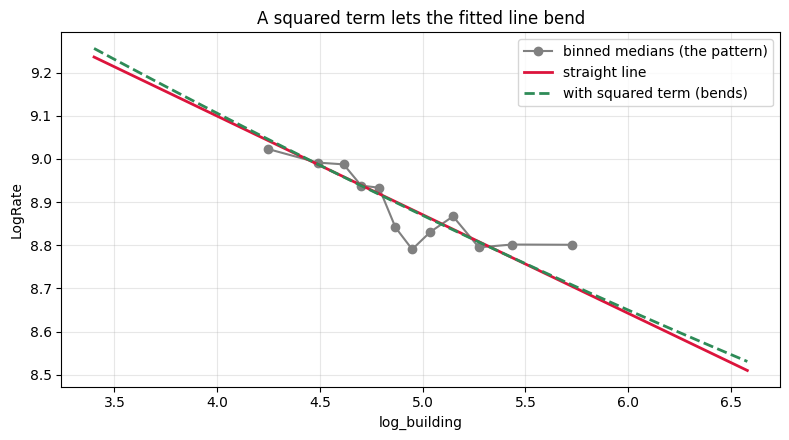

straight line     : b1 = -0.2285
with square       : b1 = -0.3151, b2 = +0.0087
training R^2      : linear 0.0596 -> quadratic 0.0597

Training R^2 can only go UP when you add a term. That is why it proves nothing
on its own - the out-of-sample check in section 15 is the one that counts.


In [14]:
d["log_building_sq"] = d["log_building"] ** 2

X_lin  = d[["log_building"]]
X_quad = d[["log_building", "log_building_sq"]]
y      = d["LogRate"]

m_lin  = LinearRegression().fit(X_lin,  y)
m_quad = LinearRegression().fit(X_quad, y)

grid = pd.DataFrame({"log_building": np.linspace(d["log_building"].min(), d["log_building"].max(), 100)})
grid["log_building_sq"] = grid["log_building"] ** 2

# Binned medians give us the "truth" to compare both fits against
q   = pd.qcut(d["log_building"], 12)
med = d.groupby(q, observed=True).agg(x=("log_building", "median"), y=("LogRate", "median"))

plt.figure(figsize=(8, 4.5))
plt.plot(med["x"], med["y"], "o-", color="grey", label="binned medians (the pattern)")
plt.plot(grid["log_building"], m_lin.predict(grid[["log_building"]]),
         color="crimson", lw=2, label="straight line")
plt.plot(grid["log_building"], m_quad.predict(grid[["log_building", "log_building_sq"]]),
         color="seagreen", lw=2, ls="--", label="with squared term (bends)")
plt.xlabel("log_building"); plt.ylabel("LogRate")
plt.title("A squared term lets the fitted line bend")
plt.legend(); plt.tight_layout(); plt.show()

print(f"straight line     : b1 = {m_lin.coef_[0]:+.4f}")
print(f"with square       : b1 = {m_quad.coef_[0]:+.4f}, b2 = {m_quad.coef_[1]:+.4f}")
print(f"training R^2      : linear {m_lin.score(X_lin, y):.4f} -> quadratic {m_quad.score(X_quad, y):.4f}")
print("\nTraining R^2 can only go UP when you add a term. That is why it proves nothing")
print("on its own - the out-of-sample check in section 15 is the one that counts.")

---
## 12. Method 6 — Residual Plot

This is one of the most important **formal** checks. After fitting a model:

```python
model.fit(X, y)
pred      = model.predict(X)
residuals = y - pred
```

$$\text{Residual} = \text{Actual} - \text{Predicted}$$

*Example:* Actual = 8.5, Predicted = 8.2 → residual = **+0.3**. Actual = 7.5, Predicted = 7.8 → residual = **−0.3**.

**What you want:** a formless cloud scattered randomly around zero — no visible pattern.

**A bad sign:** a curved or otherwise systematic shape. That means the model is missing something —
very often a nonlinear relationship it has not captured.

```python
plt.scatter(d["log_building"], residuals)
plt.axhline(0)
```

Raw residual scatter plots with thousands of points are hard to judge, so the cell below also overlays
the **mean residual per bin**. If those binned means trace an arc rather than hugging zero, you have
found left-over curvature.

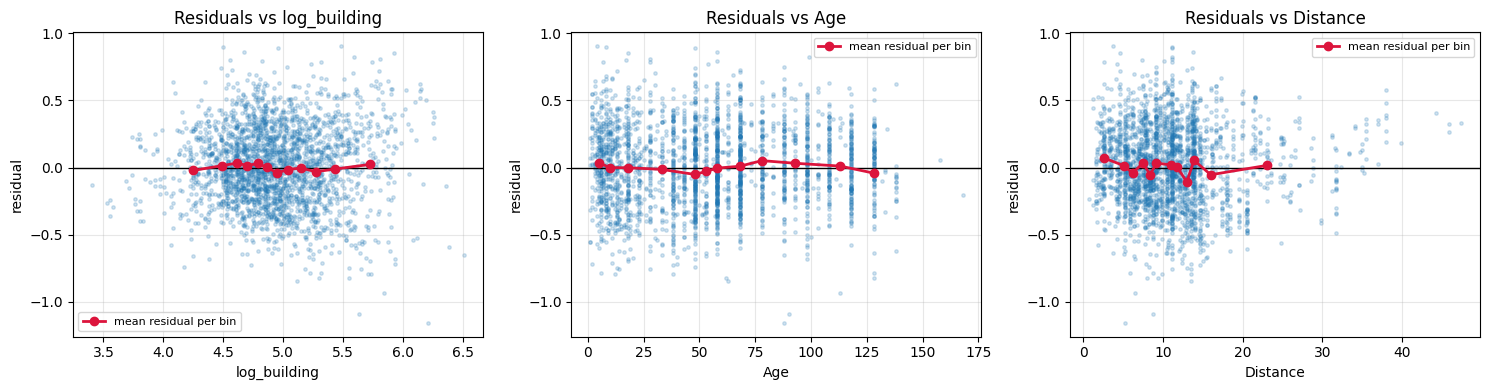

Mean residual per log_building band (all should sit near 0):
log_building
(3.4, 4.431]     -0.0136
(4.431, 4.605]    0.0189
(4.605, 4.71]     0.0217
(4.71, 4.804]     0.0277
(4.804, 4.905]    0.0068
(4.905, 5.011]   -0.0363
(5.011, 5.136]   -0.0058
(5.136, 5.278]   -0.0264
(5.278, 5.501]   -0.0136
(5.501, 6.579]    0.0191


In [15]:
# --- A full model, then its residuals -----------------------------------
FEATURES_A = ["log_building", "log_land", "Age", "Distance"]

model_A = LinearRegression().fit(d[FEATURES_A], y)
resid_A = y - model_A.predict(d[FEATURES_A])

def residual_panel(ax, xcol, residuals, bins=12):
    s = d.sample(min(2500, len(d)), random_state=0)
    ax.scatter(s[xcol], residuals.loc[s.index], s=6, alpha=0.2)
    ax.axhline(0, color="black", lw=1)
    grp = pd.DataFrame({"x": d[xcol], "r": residuals})
    grp["band"] = pd.qcut(grp["x"], bins)
    agg = grp.groupby("band", observed=True).agg(x=("x", "median"), r=("r", "mean"))
    ax.plot(agg["x"], agg["r"], "o-", color="crimson", lw=2, label="mean residual per bin")
    ax.set_xlabel(xcol); ax.set_ylabel("residual"); ax.legend(fontsize=8)
    ax.set_title(f"Residuals vs {xcol}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
residual_panel(ax[0], "log_building", resid_A)
residual_panel(ax[1], "Age",          resid_A)
residual_panel(ax[2], "Distance",     resid_A)
plt.tight_layout(); plt.show()

print("Mean residual per log_building band (all should sit near 0):")
band = pd.qcut(d["log_building"], 10)
print(resid_A.groupby(band, observed=True).mean().round(4).to_string())

**Reading our own output:** the binned mean residuals sit within roughly **±0.03**. Because the target
is a log, that is about **±3%** — small, and with no clean arc running through it. So Model A has
little left-over curvature in `log_building`. That is a genuine finding, and it correctly predicts the
result in §15.2, where the squared term turns out not to pay for itself.

Compare that with §2, where the mis-specified model's binned residuals swung from **+4.7 to −3.8** in
the units of Y and traced an unmistakable arc — while still posting a training R² of 0.958.

### 12.1 Healthy vs unhealthy — side by side

To calibrate your eye, here is a residual plot from a **correctly specified** model next to one from a
**mis-specified** model, on synthetic data where we know the truth.

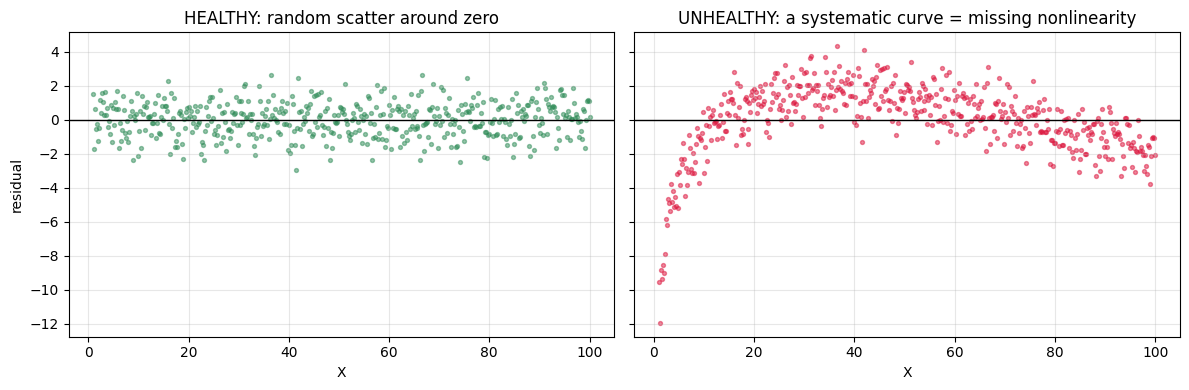

In [18]:
xs = np.linspace(1, 100, 500)
truth = 3 + 5 * np.log(xs)                          # the real relationship is in log(x)
ys = truth + rng.normal(0, 1.0, size=xs.size)

good = LinearRegression().fit(np.log(xs).reshape(-1, 1), ys)   # correct specification
bad  = LinearRegression().fit(xs.reshape(-1, 1),         ys)   # missing the log

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax[0].scatter(xs, ys - good.predict(np.log(xs).reshape(-1, 1)), s=8, alpha=0.5, color="seagreen")
ax[0].axhline(0, color="black", lw=1)
ax[0].set_title("HEALTHY: random scatter around zero")
ax[0].set_xlabel("X"); ax[0].set_ylabel("residual")

ax[1].scatter(xs, ys - bad.predict(xs.reshape(-1, 1)), s=8, alpha=0.5, color="crimson")
ax[1].axhline(0, color="black", lw=1)
ax[1].set_title("UNHEALTHY: a systematic curve = missing nonlinearity")
ax[1].set_xlabel("X")

plt.tight_layout(); plt.show()

---
## 13. Common Beginner Mistakes to Avoid

### 13.1 There Is No "Pearson > 0.5 = Linear" Rule

There is **no universal cutoff**. Combine multiple pieces of evidence instead: scatter plot, binned
medians, Pearson, Spearman, the transformed-feature comparison, the residual plot, and finally
**out-of-sample performance**.

### 13.2 Correlation vs Regression Coefficient

| Correlation | Regression coefficient |
|---|---|
| **Univariate** — just two variables, by themselves | **Multivariate** — this variable's effect *after accounting for all the others* |
| "How strongly are these two associated?" | "What is the association, **holding other variables constant**?" |

This is why a near-zero correlation is **not**, by itself, grounds for deleting a feature — the two
numbers answer different questions. `coverage` looked like noise in §9; the cell below **tests** what
it does once size and location are held constant, instead of assuming either way.

### 13.3 Linearity vs Statistical Significance

A tiny p-value (e.g. `< 0.001`) is evidence of **some** association. It says **nothing** about the
association being *linear*. A relationship can be wildly significant and strongly curved at the same
time — significance grows with sample size, not with correctness of shape.

### 13.4 Linearity vs R²

R² tells you how much variation the model explains **overall**. It does not confirm the relationship is
correctly specified as linear. A model can post a respectable R² while its residuals show obvious,
systematic curvature (we saw exactly that in §2). Always check **residual plots**, not just R² — and
always judge improvements on **out-of-sample** R², never training R².

In [19]:
# 13.2 in action: 'coverage' looked like noise univariately.
# What does it do inside a model, holding size and location constant?
print(f"Univariate Pearson(coverage, LogRate) = {d['coverage'].corr(d['LogRate']):+.4f}  (looks like nothing)")

cv = KFold(n_splits=5, shuffle=True, random_state=42)
base = ["log_building", "log_land", "Age", "Distance"]

r2_without = cross_val_score(LinearRegression(), d[base],               y, cv=cv, scoring="r2").mean()
r2_with    = cross_val_score(LinearRegression(), d[base + ["coverage"]], y, cv=cv, scoring="r2").mean()

print(f"\ncross-validated R^2 without coverage : {r2_without:.4f}")
print(f"cross-validated R^2 with    coverage : {r2_with:.4f}")
print(f"change                               : {r2_with - r2_without:+.4f}")

m = LinearRegression().fit(d[base + ["coverage"]], y)
print("\nCoefficients in the multivariate model:")
for name, c in zip(base + ["coverage"], m.coef_):
    print(f"  {name:14s} {c:+.4f}")
print("\n-> the multivariate coefficient answers a different question than the correlation did -")
print("   but here the honest answer is that coverage adds nothing. That conclusion came from")
print("   TESTING it, not from reading its correlation.")

Univariate Pearson(coverage, LogRate) = -0.0024  (looks like nothing)

cross-validated R^2 without coverage : 0.4617
cross-validated R^2 with    coverage : 0.4617
change                               : -0.0000

Coefficients in the multivariate model:
  log_building   -0.1565
  log_land       +0.0282
  Age            +0.0043
  Distance       -0.0254
  coverage       +0.0015

-> the multivariate coefficient answers a different question than the correlation did -
   but here the honest answer is that coverage adds nothing. That conclusion came from
   TESTING it, not from reading its correlation.


---
## 14. A Practical Workflow

Putting all six methods into one repeatable process:

```
                    ┌─────────────────────┐
                    │   raw feature X     │
                    └──────────┬──────────┘
                               ↓
              1. scatter plot + binned medians          ← look at the shape
                               ↓
              2. Pearson  and  3. Spearman              ← measure it
                               ↓
                    ┌──────────┴──────────┐
                    │  |S| >> |P| ?       │
                    └──────────┬──────────┘
                  no ↓                    ↓ yes
        keep X as-is                4. transform: log / sqrt
                  ↓                       ↓
                  │                 re-measure Pearson
                  │                       ↓
                  │                 still curved? → 5. add X² term
                  └──────────┬────────────┘
                             ↓
              6. fit the model, inspect RESIDUAL PLOT
                             ↓
                    residual curvature left?
                  yes ↓                  ↓ no
        revisit transform          validate on unseen data
                                   (cross-validated R²)
                                          ↓
                                    final model
```

**The rule that ties it together:** every step before the last one only *generates a hypothesis*.
A transformation or a squared term is only justified once it improves performance on data the model
has never seen.

---
## 15. Full Worked Example

### 15.1 One reusable linearity report

The function below runs methods 1–4 for a single feature in one call: correlations, the
Pearson-vs-Spearman gap, a transformation comparison, and a diagnosis.

=== BuildingArea vs LogRate ===
           version  pearson  spearman
      BuildingArea   -0.228    -0.232
 log(BuildingArea)   -0.244    -0.232
sqrt(BuildingArea)   -0.239    -0.232
signal : moderate
shape  : |Spearman| - |Pearson| = +0.004  ->  straight enough on the raw scale



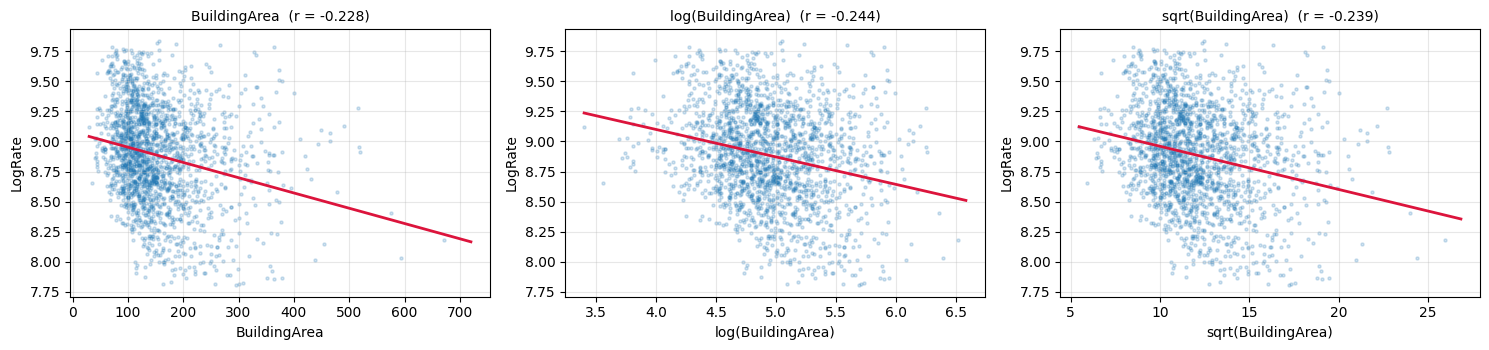

=== Landsize vs LogRate ===
       version  pearson  spearman
      Landsize   -0.026    -0.098
 log(Landsize)   -0.112    -0.098
sqrt(Landsize)   -0.074    -0.098
signal : weak (test in the model before dropping)
shape  : |Spearman| - |Pearson| = +0.072  ->  gap suggests a transformation - best tried: log(Landsize)



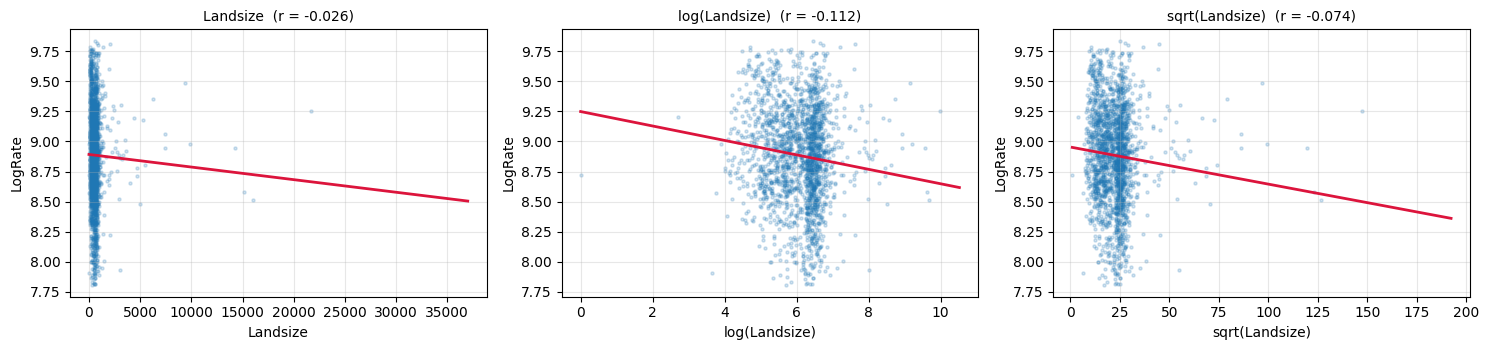

=== Age vs LogRate ===
version  pearson  spearman
    Age    0.548     0.543
signal : strong
shape  : |Spearman| - |Pearson| = -0.005  ->  straight enough on the raw scale



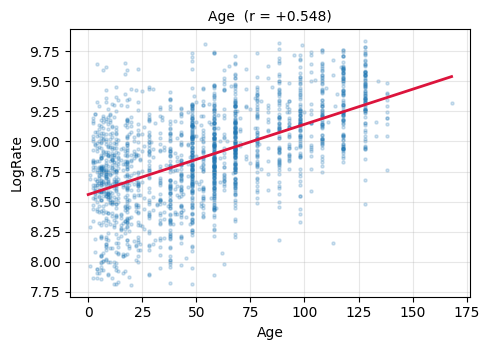

In [20]:
def linearity_report(data, feature, target="LogRate", transforms=("log", "sqrt"), plot=True):
    # Run methods 1-4 for one feature and return a tidy summary.
    x, yv = data[feature], data[target]
    p, s = x.corr(yv), x.corr(yv, method="spearman")

    rows = [{"version": feature, "pearson": round(p, 3), "spearman": round(s, 3)}]
    best_name, best_p, series = feature, abs(p), {feature: x}

    for t in transforms:
        if t == "log" and (x <= 0).any():
            continue
        if t == "sqrt" and (x < 0).any():
            continue
        xt = np.log(x) if t == "log" else np.sqrt(x)
        series[f"{t}({feature})"] = xt
        pt = xt.corr(yv)
        rows.append({"version": f"{t}({feature})", "pearson": round(pt, 3),
                     "spearman": round(xt.corr(yv, method="spearman"), 3)})
        if abs(pt) > best_p:
            best_name, best_p = f"{t}({feature})", abs(pt)

    summary = pd.DataFrame(rows)
    gap = abs(s) - abs(p)
    strength = max(abs(p), abs(s))

    signal = ("strong" if strength >= SIGNAL_STRONG else
              "moderate" if strength >= SIGNAL_SOME else
              "weak (test in the model before dropping)")
    shape = (f"gap suggests a transformation - best tried: {best_name}"
             if gap > GAP_WORTH_A_LOOK else "straight enough on the raw scale")

    print(f"=== {feature} vs {target} ===")
    print(summary.to_string(index=False))
    print(f"signal : {signal}")
    print(f"shape  : |Spearman| - |Pearson| = {gap:+.3f}  ->  {shape}\n")

    if plot:
        cols = list(series)
        fig, ax = plt.subplots(1, len(cols), figsize=(5 * len(cols), 3.6), squeeze=False)
        samp = data.sample(min(2000, len(data)), random_state=0).index
        for a, cname in zip(ax[0], cols):
            xv = series[cname]
            a.scatter(xv.loc[samp], yv.loc[samp], s=5, alpha=0.2)
            fit = np.polyfit(xv, yv, 1)
            xs_ = np.linspace(xv.min(), xv.max(), 50)
            a.plot(xs_, np.polyval(fit, xs_), color="crimson", lw=2)
            a.set_title(f"{cname}  (r = {xv.corr(yv):+.3f})", fontsize=10)
            a.set_xlabel(cname); a.set_ylabel(target)
        plt.tight_layout(); plt.show()

    return summary

_ = linearity_report(d, "BuildingArea")
_ = linearity_report(d, "Landsize")
_ = linearity_report(d, "Age", transforms=())

### 15.2 The final step nobody should skip: validate out-of-sample

We now have a hypothesis: `log_building` curves a little, so a squared term might help.
Methods 1–6 can only *suggest* that. **Cross-validation decides it.**

| Model | Specification |
|---|---|
| **A** | `LogRate ~ log_building + log_land + Age + Distance` |
| **B** | Model A **+ `log_building²`** |
| **C** | Model A on **raw** `BuildingArea` / `Landsize` (no logs) |

In [21]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

MODELS = {
    "A: logs, linear":      ["log_building", "log_land", "Age", "Distance"],
    "B: A + log_building^2": ["log_building", "log_land", "Age", "Distance", "log_building_sq"],
    "C: raw sizes":         ["BuildingArea", "Landsize", "Age", "Distance"],
}

rows = []
for name, feats in MODELS.items():
    scores = cross_val_score(LinearRegression(), d[feats], y, cv=cv, scoring="r2")
    fitted = LinearRegression().fit(d[feats], y)
    rows.append({"model": name,
                 "train R^2": round(fitted.score(d[feats], y), 4),
                 "CV R^2 (mean)": round(scores.mean(), 4),
                 "CV R^2 (std)": round(scores.std(), 4)})

results = pd.DataFrame(rows)
print(results.to_string(index=False))

best = results.loc[results["CV R^2 (mean)"].idxmax(), "model"]
print(f"\nBest out-of-sample model: {best}")

                model  train R^2  CV R^2 (mean)  CV R^2 (std)
      A: logs, linear     0.4626         0.4617        0.0178
B: A + log_building^2     0.4627         0.4616        0.0178
         C: raw sizes     0.4582         0.4574        0.0171

Best out-of-sample model: A: logs, linear


### 15.3 How to read that result — including when the answer is "no"

Two things are worth sitting with:

1. **The log transforms earn their place.** Model A beats Model C, so `log(BuildingArea)` and
   `log(Landsize)` are genuinely better representations than the raw columns — exactly what the
   Pearson-vs-Spearman gap in §9 predicted.

2. **The squared term does not.** Model B's *training* R² is greater than or equal to Model A's — it
   always will be, since adding a term can never reduce training fit. But its **cross-validated** R²
   is essentially unchanged or slightly worse. The mild curvature we saw in §5.1 and §12 is real but
   **too small to pay for an extra parameter.**

> 🎯 **This is the lesson, not a failed experiment.** A linearity check is an *investigation*, and
> "the curvature is not worth modelling" is a perfectly good — and common — conclusion. Had we
> stopped at training R², we would have wrongly kept the squared term.

Summary of what the full check produced on this dataset:

| Step | Finding |
|---|---|
| 1. Raw plots / binned medians | median Rate falls with building size, steeply then flattening → curved |
| 2. Correlations | `Age`, `Distance` roughly linear; `Landsize` shows the nonlinear signature; `coverage` weak univariately |
| 3. Transform | `log_building`, `log_land` created |
| 4. Recalculate | Pearson improves for both → the logs made the relationships more linear |
| 5. Investigate curvature | `log_building_sq` created and tested |
| 6. Compare out-of-sample | logs kept (A > C); **squared term rejected** (B ≈ A) |

---
## 16. The Most Important Takeaway

The entire linearity check answers three simple questions, in order:

1. **Is there a relationship at all?** — Pearson / Spearman correlation.
2. **Is it roughly a straight line?** — scatter plots and the Pearson-vs-Spearman gap.
3. **If curved, can we transform it to make it (more) linear?** — try `log(X)`, `sqrt(X)` or `X²`,
   and **validate on unseen data**.

> 🎯 **In one sentence:** Linearity checking is not simply checking whether Pearson correlation is
> high — it is the process of discovering whether a feature has a relationship with the target,
> determining whether that relationship is approximately straight, identifying curvature through plots
> and Pearson-vs-Spearman comparisons, transforming the feature when appropriate, and finally
> **verifying that the transformation actually improves out-of-sample model performance**.

### Quick reference

| Symptom | Likely meaning | Action |
|---|---|---|
| abs(Pearson) ≈ abs(Spearman), both high | strong **and** linear | use as-is |
| abs(Spearman) ≫ abs(Pearson) | monotonic but curved | `log` / `sqrt`, then re-measure |
| both ≈ 0, scatter shows a U | non-monotonic (e.g. `X²`) | add a squared term |
| both ≈ 0, scatter shows nothing | no *univariate* signal | keep and test multivariately — don't drop on correlation alone |
| residuals trace an arc | missing nonlinearity | revisit the transformation |
| training R² up, cross-validated R² flat | the extra term is overfitting | drop the extra term |

**One last habit worth forming:** run the check on the *training* data only. Deciding a
transformation by looking at the test set leaks information, and the out-of-sample R² you report
afterwards will be optimistic.